# 04 基于 NetworkX 的最短路径问题求解

> **模块**：图论与网络 ｜ **数据**：无（内置示例） ｜ **依赖**：numpy、matplotlib、networkx

## 1. 问题背景

最短路径问题是图论中非常经典的问题之一，旨在寻找图中两项点之间的最短路径。也就是在一个有向或无向的加权图中，找到两个顶点之间的最短路径，即路径上边的权重之和最小的路径。作为一个基本工具，实际应用中的许多优化问题，如管道铺设、线路安排、厂区布局、设备更新等，都可被归结为最短路径问题来解决。


## 2. 学习目标

- 掌握迪杰斯特拉算法的思路
- 掌握使用 NetworkX 计算 Dijkstra 最短路径


## 3. 环境与数据

- Jupyter 开发环境
- Python 3.10


## 4. 方法与实现

### 4.1 迪杰斯特拉（Dijkstra）算法

Djkstra算法是一种用于计算带权有向图中单源最短路径(SSSP:Single-Source Shortest Path)的算法，由计算机科学家Edsger Djkstra于1956年构思并于1959年发表。其解决的问题是:给定图和源顶点v，找到从v至图中所有顶点的最短路径。

Djkstra算法采用的是一种贪心的策略。

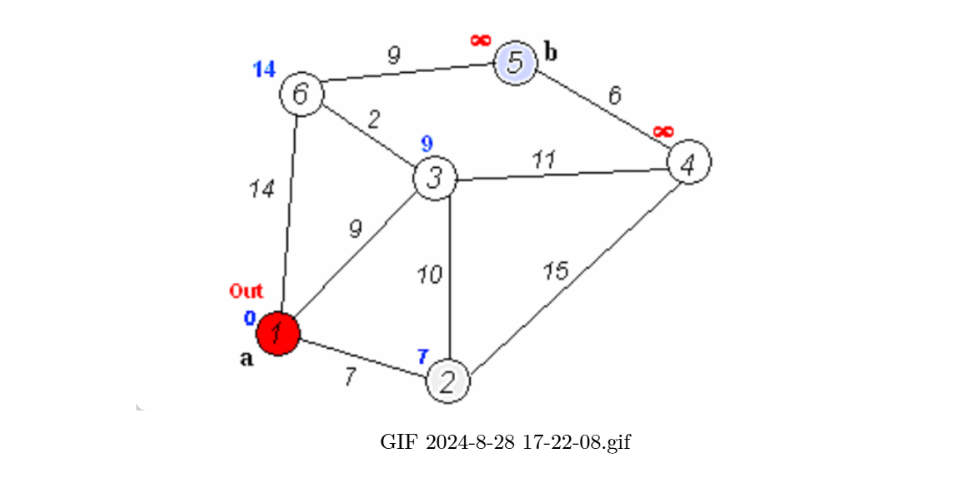

Djkstra算法的基本思想是：按距离固定起点顶点从近到远为顺序，一次求得起点顶点到终点顶点的最短路径和距离

Djkstra算法具体步骤如下：
1. 确定开始和结束顶点a和b

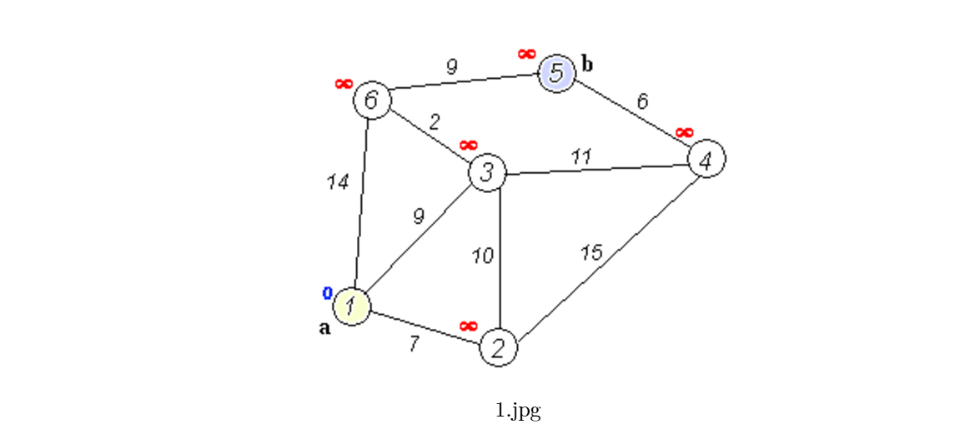

2. 顶点1到达其它顶点的权值

|  顶点   | 2  |  3   | 4  |  5   | 6  |
|  :---: |:---: |:---: |:---: |:---: |:---: |
| 总权值   | 7  |  9   | $∞$  |  $∞$   | 14  |
| 路径   | 1-2  |  1-3   | 1-4  |  1-5   | 1-6  |

$∞$表示两个顶点之间无法直达，对应的权值为无穷大。

比较权值找到最短路径1-2。

3. 最短路径表格继续更新直到到达结束顶点

3.1遍历与顶点2相邻的顶点更新最短路径表

|  顶点   | 2  |  3   | 4  |  5   | 6  |
|  :---: |:---: |:---: |:---: |:---: |:---: |
| 总权值   | 7  |  9   | 22  |  $∞$   | 14  |
| 路径   | 1-2  |  1-3   | 1-2-4  |  1-5   | 1-6  |

3.2遍历与顶点3相邻的顶点更新最短路径表

|  顶点   | 2  |  3   | 4  |  5   | 6  |
|  :---: |:---: |:---: |:---: |:---: |:---: |
| 总权值   | 7  |  9   | 20  |  $∞$   | 11  |
| 路径   | 1-2  |  1-3   | 1-3-4  |  1-5   | 1-3-6  |

同理遍历4，5，6顶点后得到最终的最短路径表

|  顶点   | 2  |  3   | 4  |  5   | 6  |
|  :---: |:---: |:---: |:---: |:---: |:---: |
| 总权值   | 7  |  9   | 20  |  20   | 11  |
| 路径   | 1-2  |  1-3   | 1-3-4  |  1-3-6-5   | 1-3-6  |

所以顶点1到顶点5的最短路径为1-3-6-5，最短距离为20。

> *原稿配图未随 notebook 保存，此处暂缺。*

接下来我们使用Python实现上述算法。

#### 4.1.1 自定义函数计算

首先得到邻接矩阵：

$$
\begin{bmatrix}
0 & 7 & 9 & ∞ & ∞ & 14\\
7 & 0 & 10 & 15 & ∞ & ∞\\
9 & 10 & 0 & 11 & ∞ & 2\\
∞ & 15 & 11 & 0 & 6 & ∞\\
∞ & ∞ & ∞ & 6 & 0 & 9\\
14 & ∞ & 2 & ∞ & 9 & 0
\end{bmatrix}

$$

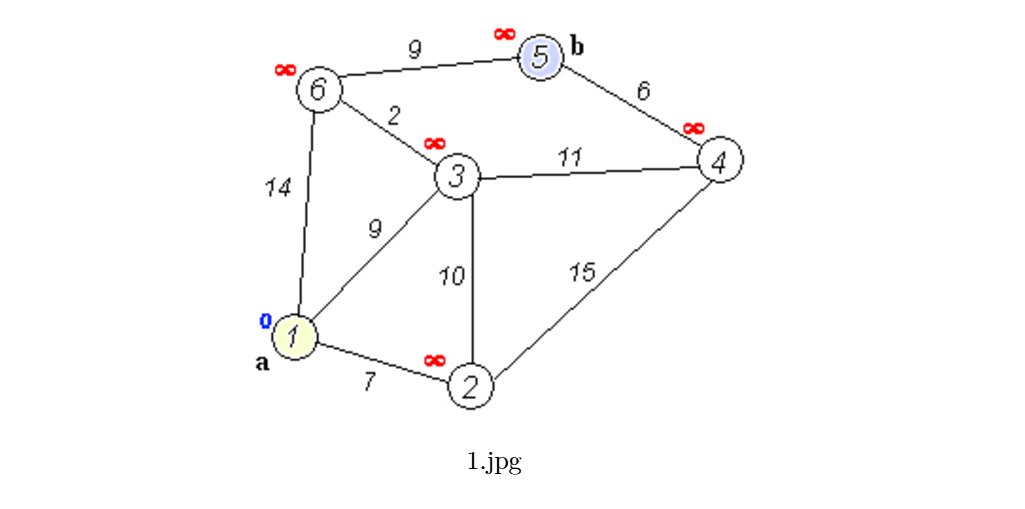
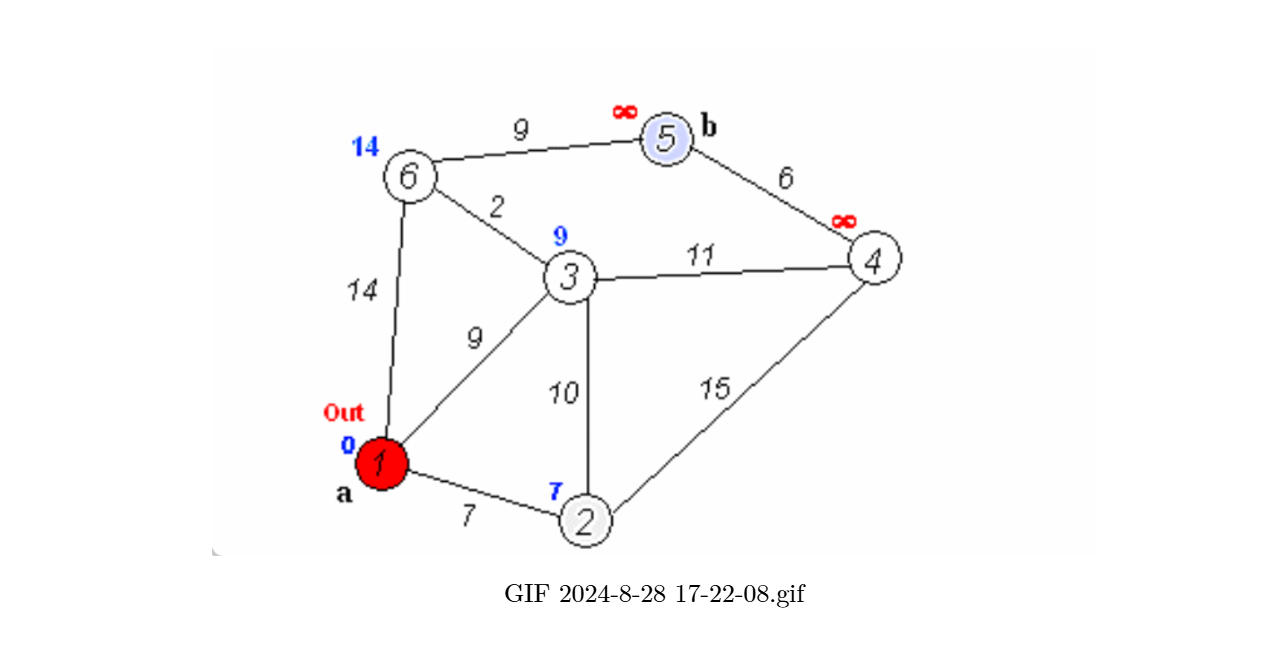

In [1]:
import networkx as nx
import matplotlib.pyplot as plt
import numpy as np

# 设置无穷值
inf = np.inf

# 创建邻接矩阵
A = np.array([
    [0, 7, 9, inf, inf, 14],
    [7, 0, 10, 15, inf, inf],
    [9, 10, 0, 11, inf, 2],
    [inf, 15, 11, 0, 6, inf],
    [inf, inf, inf, 6, 0, 9],
    [14, inf, 2, inf, 9, 0]
])

A


array([[ 0.,  7.,  9., inf, inf, 14.],
       [ 7.,  0., 10., 15., inf, inf],
       [ 9., 10.,  0., 11., inf,  2.],
       [inf, 15., 11.,  0.,  6., inf],
       [inf, inf, inf,  6.,  0.,  9.],
       [14., inf,  2., inf,  9.,  0.]])

In [2]:
def Dijkstra_all_minpath(matr, start):
    '''
    使用Dijkstra算法计算从固定起点到所有其他节点的最短路径及其最短距离
    :param matr: 邻接矩阵，表示图中各节点间的距离
    :param start: 起点节点的索引
    :return: 从起点到其他所有节点的最短距离数组
    '''
    n = len(matr)  # 获取图中的节点总数
    dis = []  # 初始化距离数组dis，保存从起点到各节点的最短距离
    temp = []  # 初始化临时数组temp，用于每次循环中保存未处理节点的当前最短距离
    dis.extend(matr[start])  # dis初始值为起点对应的邻接矩阵行
    temp.extend(matr[start])  # temp初始值与dis相同
    
    temp[start] = float('inf')  # 将已处理过的节点的值在临时数组temp中设为无穷大，避免重复处理
    visited = [start]  # 记录已处理过的节点，初始时只有起点
    parent = [start] * n  # 初始化parent数组，用于记录最短路径中每个节点的前驱节点，初始时所有节点的前驱都设为起点
    
    while len(visited) < n:  # 当所有节点都未被处理时，持续循环
        i = temp.index(min(temp))  # 在temp中找到距离最小的节点的索引i
        temp[i] = float('inf')  # 将该节点标记为已处理，即在temp中设为无穷大
        
        for j in range(n):  # 对于每个节点j，如果j未被处理
            if j not in visited:
                if (dis[i] + matr[i][j]) < dis[j]:  # 比较当前dis[j]和通过节点i到达j的距离
                    dis[j] = temp[j] = dis[i] + matr[i][j]  # 如果通过节点i到达j的距离更短，则更新dis[j]和temp[j]
                    parent[j] = i  # 记录节点j的前驱节点为i
        
        visited.append(i)  # 将节点i添加到已处理节点列表visited中
        path = []  # 初始化路径数组path，用于保存从起点到节点i的路径
        path.append(str(i))  # 从i开始记录路径
        k = i
        
        while parent[k] != start:  # 根据parent数组反向查找从起点到节点i的路径
            path.append(str(parent[k]))
            k = parent[k]
        
        path.append(str(start))  # 最后添加起点到路径数组中，表示完整路径
        path.reverse()  # 反转路径数组，使其从起点到终点
        print(str(i) + ':', '->'.join(path))  # 打印节点i的最短路径
    
    return dis  # 返回从起点到所有其他节点的最短距离数组


In [3]:
# 放入邻接矩阵和起点顶点0
distance = Dijkstra_all_minpath(A,0)
distance

1: 0->1
2: 0->2
5: 0->2->5
3: 0->2->3
4: 0->2->5->4


[np.float64(0.0),
 np.float64(7.0),
 np.float64(9.0),
 np.float64(20.0),
 np.float64(20.0),
 np.float64(11.0)]

#### 4.1.2 NetworkX 计算

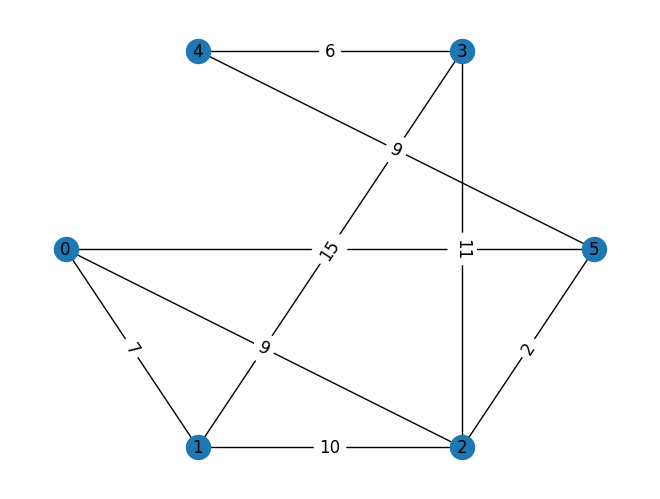

In [4]:
import networkx as nx
import matplotlib.pyplot as plt

# 定义边和权重
edges = [(0,1,7),(0,2,9),(0,5,14),(1,2,10),(1,3,15),(2,3,11),(2,5,2),(3,4,6),(4,5,9)]

# 创建无向图并添加边
G = nx.Graph()
G.add_weighted_edges_from(edges)

# 使用shell布局
pos = nx.shell_layout(G)

# 获取边的权重
weights = nx.get_edge_attributes(G, 'weight')

# 绘制图和边权重
nx.draw(G, pos, with_labels=True)
nx.draw_networkx_edge_labels(G, pos, edge_labels=weights, font_size=12)
plt.show()


In [5]:
# 生成图G的邻接矩阵
# nodelist顶点列表，若不设置则按照排序由 G.nodes() 生成
A = nx.to_numpy_array(G, nodelist=range(6))  
A

array([[ 0.,  7.,  9.,  0.,  0., 14.],
       [ 7.,  0., 10., 15.,  0.,  0.],
       [ 9., 10.,  0., 11.,  0.,  2.],
       [ 0., 15., 11.,  0.,  6.,  0.],
       [ 0.,  0.,  0.,  6.,  0.,  9.],
       [14.,  0.,  2.,  0.,  9.,  0.]])

In [6]:

# 计算从源到目标的最短加权路径
p = nx.dijkstra_path(G, source=0, target=4, weight='weight')  # 计算从源节点0到目标节点4的最短加权路径
d = nx.dijkstra_path_length(G, 0, 4, weight='weight')  # 计算从源节点0到目标节点4的最短加权路径长度
print('最短路径为:', p)
print('最短距离为:', d)


最短路径为: [0, 2, 5, 4]
最短距离为: 20


### 4.2 最短路径问题应用

#### 4.2.1 设备更新问题

某种工程设备的役龄为4年，每年年初都面临着是否更新的问题：若卖旧买新，就要支付一定的购置费用；若继续使用，则要支付更多的维护费用，且使用年限越长维护费用越多。若役龄期内每年的年初购置价格、当年维护费用及年末剩余净值如下表所示。请为该设备制定一个4年役龄期内的更新计划，使总的支付费用最少。

**表1：设备每年年初购置价格、当年维护费用及年末剩余净值表**

| 年份 | 1 | 2 | 3 | 4 |
| ---- | - | - | - | - |
| 年初购置价格/万元 | 25 | 26 | 28 | 31 |
| 当年维护费用/万元 | 10 | 14 | 18 | 26 |
| 年末剩余净值/万元 | 20 | 16 | 13 | 11 |

可以把这个问题化为图论中的最短路问题。构造赋权有向图$D = (V,A,W)$，其中顶点集$V = \{v_1,v_2,v_3,v_4,v_5\}$，这里$v_i(i=1,2,3,4)$表示第$i$年年初的时刻，$v_5$表示第4年年末的时刻，$A$为弧的集合，邻接矩阵$W = {(w_{ij})}_{5×5}$ ，这里$w_{ij}$为第$i$年年初至第$j$年年初（或$j-1$年年末）期间所支付的费用，计算公式为

$$
w _ { i j } = p _ { i } + \sum _ { k = 1 } ^ { j - i } a _ { k } - r _ { j - i }

$$

其中$p_i$为第$i$年年初的购置价格，$a_k$为使用到第$k$年当年的维护费用，$r_i$为使用$i$年旧设备的出售价格（残值）。

根据以上公式，得到如下邻接矩阵$W$。

$$
W =
\begin{bmatrix}
0 & 15 & 33 & 54 & 82 \\
\infty & 0 & 16 & 34 & 55 \\
\infty & \infty & 0 & 18 & 36 \\
\infty & \infty & \infty & 0 & 21 \\
\infty & \infty & \infty & \infty & \infty
\end{bmatrix}

$$

那么制订总的支付费用最小的设备更新计划，就是在如上邻接矩阵的有向图$D$中求顶点$v_1$到顶点$v_5$的费用最短路径。

In [7]:
# 先定义三个向量值
p = np.array([25, 26, 28, 31])
a = np.array([10, 14, 18, 26])
r = np.array([20, 16, 13, 11])

# 邻接矩阵初始化
w = np.zeros((5, 5))

# 循环 根据公式求wij
for i in range(5):
    for j in range(i + 1, 5):
        w[i, j] = p[i] + np.sum(a[0:j - i]) - r[j - i - 1]  # 计算邻接矩阵元素wij
w


array([[ 0., 15., 33., 54., 82.],
       [ 0.,  0., 16., 34., 55.],
       [ 0.,  0.,  0., 18., 36.],
       [ 0.,  0.,  0.,  0., 21.],
       [ 0.,  0.,  0.,  0.,  0.]])

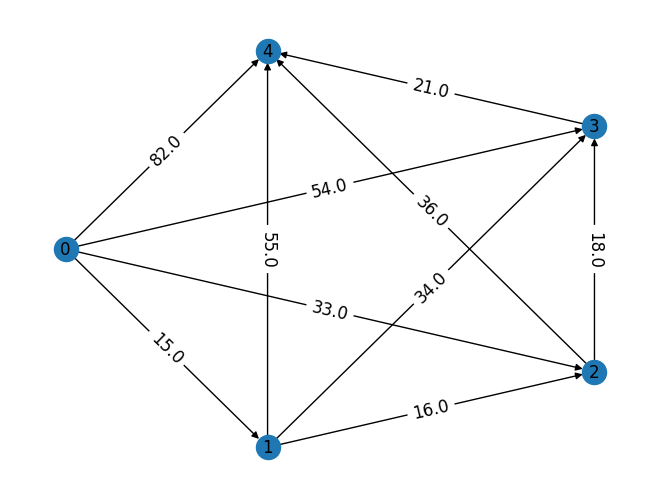

In [8]:
# 创建有向图，放入邻接矩阵w
G = nx.DiGraph(w)
# 节点在同心圆上分布
pos=nx.shell_layout(G)
# 从G中获取弧的权值
w = nx.get_edge_attributes(G,'weight')
# 绘图
nx.draw(G,pos,with_labels=True)
nx.draw_networkx_edge_labels(G,pos,font_size=12,edge_labels=w)
plt.show()

In [9]:

p = nx.dijkstra_path(G, source=0, target=4, weight='weight')  # 计算最短路径，放入有向图，起始顶点和结束顶点 
print("最短路径为:",np.array(p)+1)  

d = nx.dijkstra_path_length(G, 0, 4, weight='weight')  # 计算最短路径对应的最短距离，也就是最小费用
print("所求的费用最小值为：",d,"（万元）")

最短路径为: [1 2 3 5]
所求的费用最小值为： 67.0 （万元）


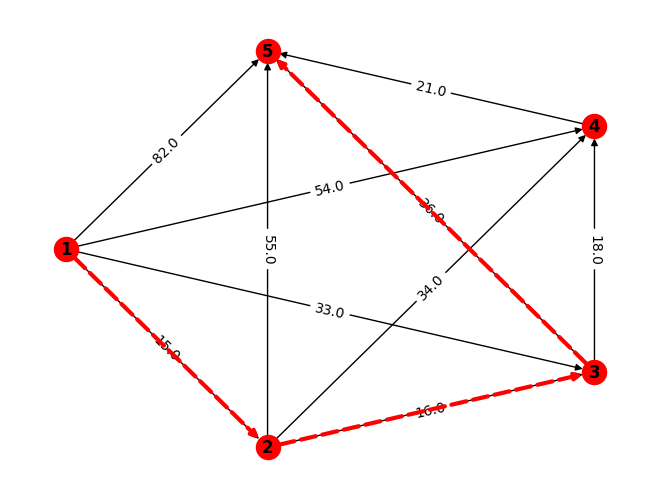

In [10]:
pos=nx.shell_layout(G)   # 节点在同心圆上分布
w=nx.get_edge_attributes(G,'weight') # 从G中获取弧的权值
s=dict(zip(range(5),range(1,6)))   # 构造用于顶点标注的标号字典

# 绘图
# labels设置顶点标签
# node_color='r'指定节点颜色为红色
nx.draw(G,pos,font_weight='bold',labels=s,node_color='r')
nx.draw_networkx_edge_labels(G,pos,edge_labels=w)

path_edges=list(zip(p,p[1:]))  # 获取最短路径的所有弧

nx.draw_networkx_edges(G,pos,edgelist=path_edges,edge_color='r',width=3,style="dashed")  # 对最短路径的弧绘制为红色（style="dashed"表示虚线）


由上述结果可以得到$v_1$到$v_5$的最短路径为$v_1→v_2→v_3→v_5$，最短路径长度为67。

即设备更新计划为：
1. 第一年年初买进新设备，使用到第一年年底卖出
2. 第二年年初买进新设备，使用到第二年年底卖出
3. 第三年年初买进新设备，使用到第四年年度卖出

共支付费用67万元。


## 5. 小结

本次实验介绍了迪杰斯特拉算法的基本思路和一般步骤，并且通过一个实例使用自定义函数和networkx库两种方法计算Dijkstra最短路径。

通过本次实验需要掌握以下内容：
- 掌握迪杰斯特拉算法的思路
- 掌握使用networkx计算Dijkstra最短路径
